In [4]:
!pip install xgboost scikit-learn shap SkillMetrics -q

In [5]:
import os
import time
import logging
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import skill_metrics as sm
from scipy.stats import wilcoxon
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from google.colab import files

logging.getLogger("joblib").setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

In [6]:
print("Memuat data...")
if not os.path.exists('/content/dataset_clean.csv'):
    files.upload()

df = pd.read_csv('/content/dataset_clean.csv')

kolom_teks = df.select_dtypes(include=['object']).columns
for col in kolom_teks:
    if df[col].astype(str).str.contains('POINT').any():
        df['Longitude'] = df[col].str.extract(r'POINT \(([-0-9.]+)')[[0]].astype(float)
        df['Latitude'] = df[col].str.extract(r'POINT \([-0-9.]+ ([-0-9.]+)\)')[[0]].astype(float)

df = df.select_dtypes(exclude=['object'])
if len(df) > 200000:
    df = df.sample(n=200000, random_state=42)

fitur_terbaik = [
    'Vp_7000m', 'crustal_thickness', 'dVs_20km', 'Vp_6000m',
    'VpVs_60km', 'dVs_60km', 'gg_mantle_60km', 'dVpVs_60km',
    'dVs_40km', 'elevation_detrend'
]
fitur_terbaik = [f for f in fitur_terbaik if f in df.columns]
target_cols = ['T_1000m', 'T_2000m', 'T_3000m', 'T_4000m', 'T_5000m']

X = df[fitur_terbaik].values
y_multi = df[target_cols].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Memuat data...


In [7]:
best_p = {
    'rf_n_estimators': 250,
    'rf_max_depth': 19,
    'xgb_n_estimators': 300,
    'xgb_max_depth': 11,
    'xgb_learning_rate': 0.0726521095850301
}

rf_base = RandomForestRegressor(
    n_estimators=best_p['rf_n_estimators'],
    max_depth=best_p['rf_max_depth'],
    random_state=42,
    n_jobs=-1
)

xgb_base = XGBRegressor(
    n_estimators=best_p['xgb_n_estimators'],
    max_depth=best_p['xgb_max_depth'],
    learning_rate=best_p['xgb_learning_rate'],
    random_state=42,
    n_jobs=-1
)

model_rf = MultiOutputRegressor(rf_base)
model_xgb = MultiOutputRegressor(xgb_base)
model_stack = MultiOutputRegressor(
    StackingRegressor(
        estimators=[('rf', rf_base), ('xgb', xgb_base)],
        final_estimator=LinearRegression(),
        cv=3,
        n_jobs=-1
    )
)

models = {
    'Random Forest': model_rf,
    'XGBoost': model_xgb,
    'Hybrid Stacking': model_stack
}

In [8]:
print("Evaluasi 5-Fold...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
metrics = {m: {col: {'rmse': [], 'r2': []} for col in target_cols} for m in models}
abs_errors = {m: {col: [] for col in target_cols} for m in models}
y_pred_cv_stack = np.zeros_like(y_multi)

fold_idx = 1
t0 = time.time()
for train_idx, test_idx in kf.split(X_scaled):
    print(f"Fold {fold_idx}/5...")
    X_tr, X_te = X_scaled[train_idx], X_scaled[test_idx]
    y_tr, y_te = y_multi[train_idx], y_multi[test_idx]

    for name, mdl in models.items():
        mdl.fit(X_tr, y_tr)
        preds = mdl.predict(X_te)
        if name == 'Hybrid Stacking':
            y_pred_cv_stack[test_idx] = preds

        for i, col in enumerate(target_cols):
            rmse = np.sqrt(mean_squared_error(y_te[:, i], preds[:, i]))
            r2 = r2_score(y_te[:, i], preds[:, i])
            metrics[name][col]['rmse'].append(rmse)
            metrics[name][col]['r2'].append(r2)
            abs_errors[name][col].extend(np.abs(y_te[:, i] - preds[:, i]))
    fold_idx += 1

print(f"Evaluasi selesai: {(time.time() - t0)/60:.2f} menit")

table_rows = []
for col in target_cols:
    row = {'Target Depth': col}
    for m in models:
        row[f'RMSE_{m}'] = np.mean(metrics[m][col]['rmse'])
        row[f'R2_{m}'] = np.mean(metrics[m][col]['r2'])

    _, p_rf = wilcoxon(abs_errors['Hybrid Stacking'][col], abs_errors['Random Forest'][col])
    _, p_xgb = wilcoxon(abs_errors['Hybrid Stacking'][col], abs_errors['XGBoost'][col])
    row['p-value (Hybrid vs RF)'] = p_rf
    row['p-value (Hybrid vs XGB)'] = p_xgb
    table_rows.append(row)

df_table4 = pd.DataFrame(table_rows)
overall = {'Target Depth': 'Overall Average'}
for c in df_table4.columns:
    if c != 'Target Depth':
        overall[c] = df_table4[c].mean()
df_table4.loc[len(df_table4)] = overall
df_table4.to_excel('Ablation_Study_Comparison_Table.xlsx', index=False)
display(df_table4)

Evaluasi 5-Fold...
Fold 1/5...
Fold 2/5...
Fold 3/5...
Fold 4/5...
Fold 5/5...
Evaluasi selesai: 417.09 menit


,Target Depth,RMSE_Random Forest,R2_Random Forest,RMSE_XGBoost,R2_XGBoost,RMSE_Hybrid Stacking,R2_Hybrid Stacking,p-value (Hybrid vs RF),p-value (Hybrid vs XGB)
0,T_1000m,3.026020,0.887496,2.931035,0.894419,2.883224,0.897837,1.504221e-43,0.0
1,T_2000m,3.388230,0.930537,3.325603,0.933082,3.258731,0.935745,3.360968e-01,0.0
2,T_3000m,3.788928,0.947114,3.758609,0.947957,3.674016,0.950274,8.280049e-18,0.0
3,T_4000m,4.125582,0.959018,4.114893,0.959231,4.011778,0.961249,8.280210e-11,0.0
4,T_5000m,4.598918,0.966181,4.556613,0.966800,4.459578,0.968199,1.527428e-52,0.0
5,Overall Average,3.785536,0.938069,3.737351,0.940298,3.657465,0.942661,6.721936e-02,0.0


In [9]:
print("Training model final...")
model_stack.fit(X_scaled, y_multi)
print("Training selesai.")

Training model final...
Training selesai.


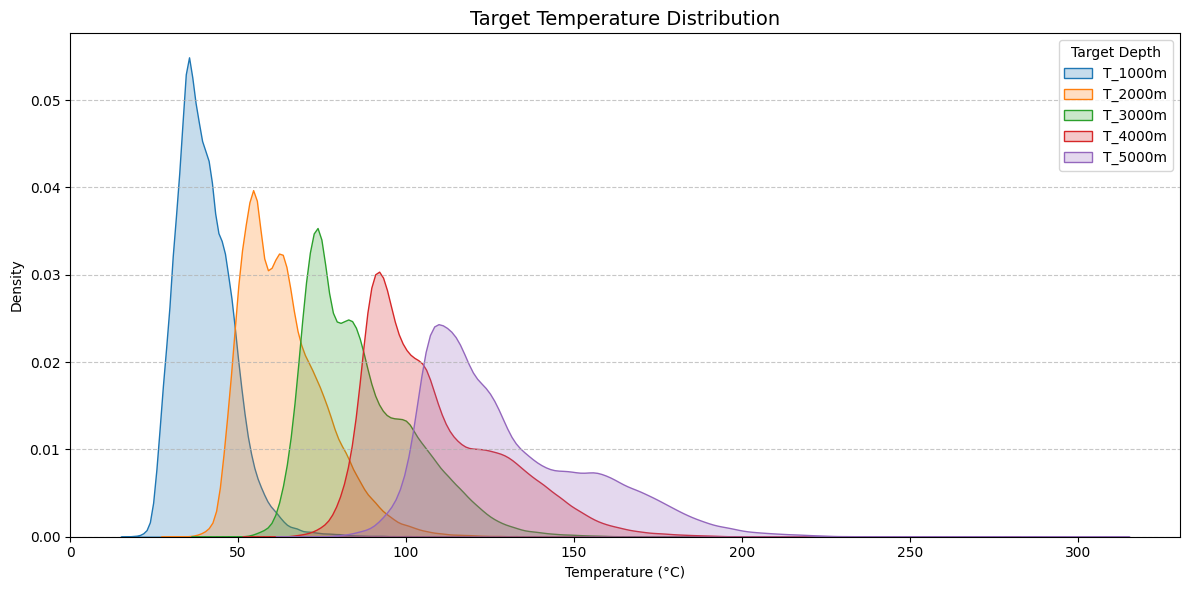

In [10]:
plt.figure(figsize=(12, 6))
for col in target_cols:
    sns.kdeplot(df[col], fill=True, label=col)
plt.title('Target Temperature Distribution', fontsize=14)
plt.xlabel('Temperature (°C)')
plt.ylabel('Density')
plt.legend(title='Target Depth')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('Visual_D_Data_Distribution.png', dpi=300)
plt.show()

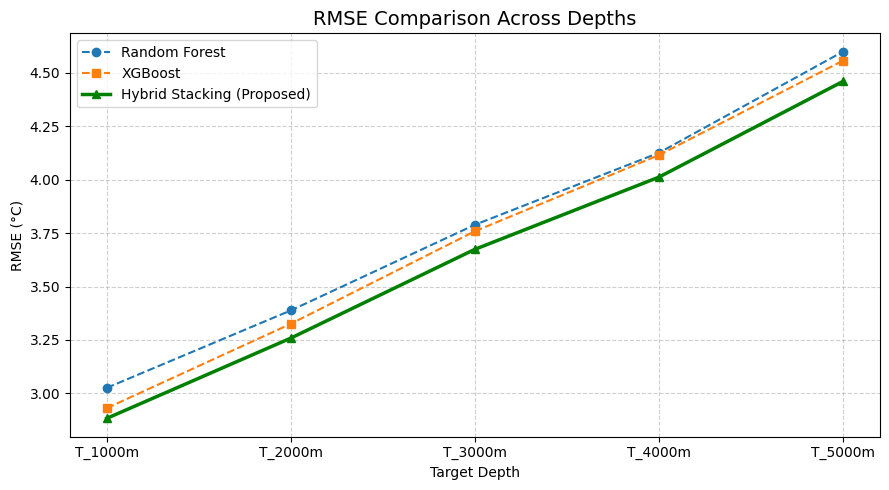

In [11]:
df_plot = df_table4[df_table4['Target Depth'] != 'Overall Average'].copy()
plt.figure(figsize=(9, 5))
plt.plot(df_plot['Target Depth'], df_plot['RMSE_Random Forest'], marker='o', label='Random Forest', linestyle='--')
plt.plot(df_plot['Target Depth'], df_plot['RMSE_XGBoost'], marker='s', label='XGBoost', linestyle='--')
plt.plot(df_plot['Target Depth'], df_plot['RMSE_Hybrid Stacking'], marker='^', label='Hybrid Stacking (Proposed)', linewidth=2.5, color='green')
plt.title('RMSE Comparison Across Depths', fontsize=14)
plt.xlabel('Target Depth')
plt.ylabel('RMSE (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Output_3_RMSE_vs_Depth.png', dpi=300)
plt.show()

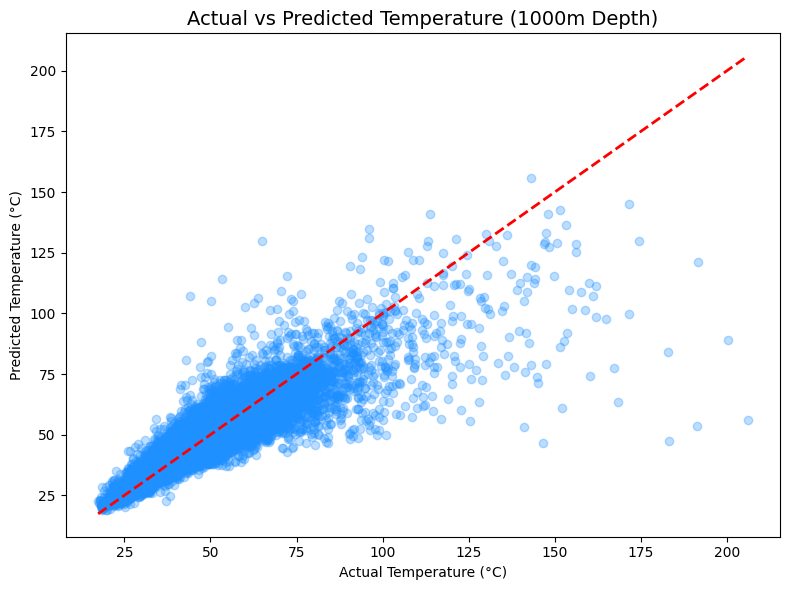

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(y_multi[:, 0], y_pred_cv_stack[:, 0], alpha=0.3, color='dodgerblue')
plt.plot([y_multi[:, 0].min(), y_multi[:, 0].max()], [y_multi[:, 0].min(), y_multi[:, 0].max()], 'r--', lw=2)
plt.xlabel('Actual Temperature (°C)')
plt.ylabel('Predicted Temperature (°C)')
plt.title('Actual vs Predicted Temperature (1000m Depth)', fontsize=14)
plt.tight_layout()
plt.savefig('Visual_A_Actual_vs_Predicted.png', dpi=300)
plt.show()

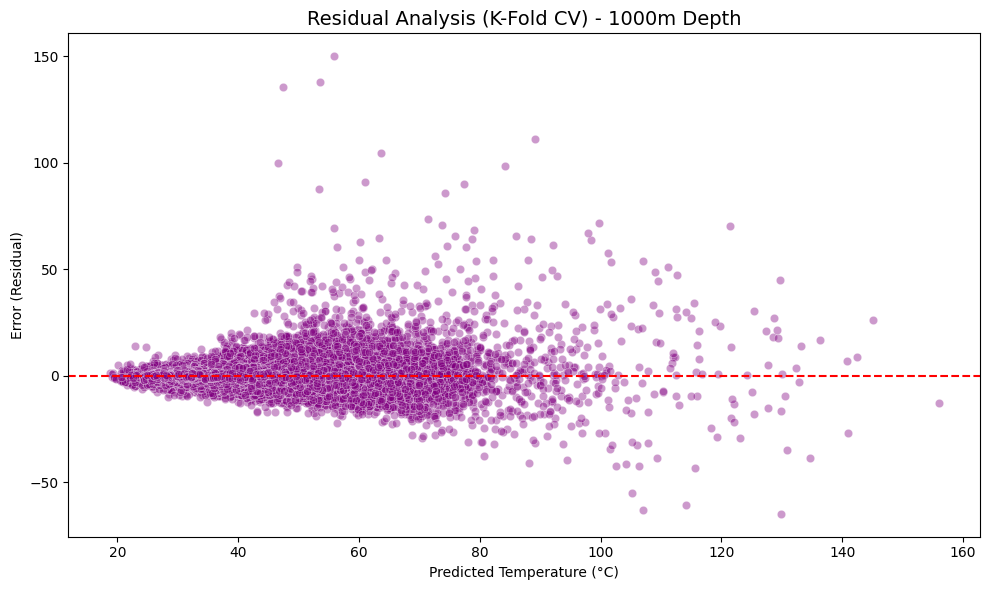

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred_cv_stack[:, 0], y=(y_multi[:, 0] - y_pred_cv_stack[:, 0]), alpha=0.4, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Temperature (°C)')
plt.ylabel('Error (Residual)')
plt.title('Residual Analysis (K-Fold CV) - 1000m Depth', fontsize=14)
plt.tight_layout()
plt.savefig('Visual_B_Residual_Plot.png', dpi=300)
plt.show()

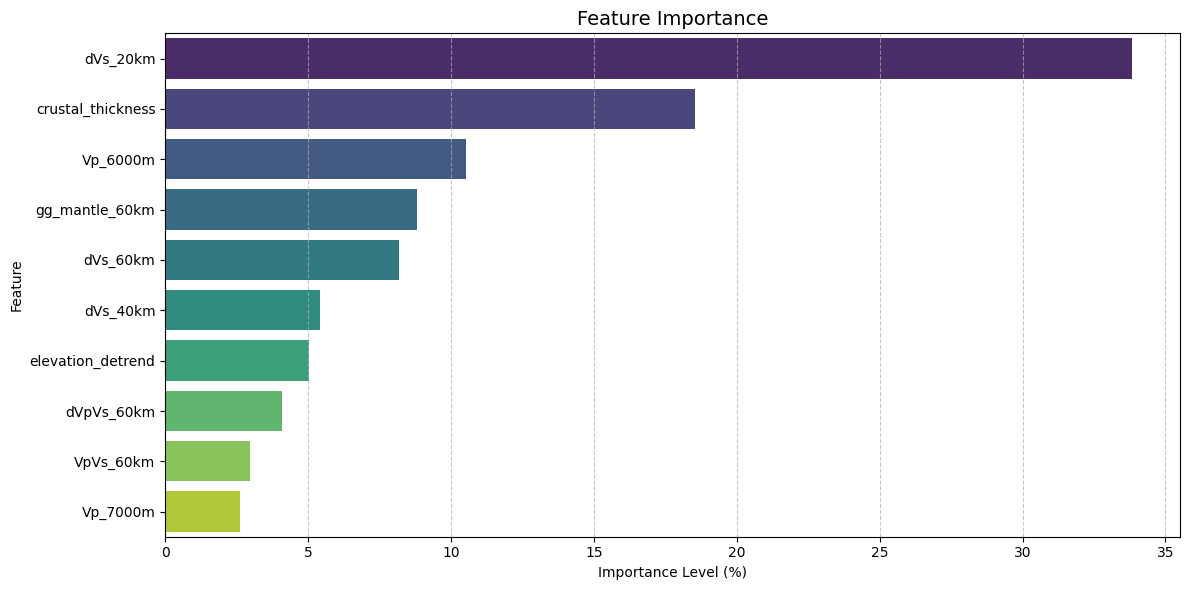

In [14]:
rf_est = model_stack.estimators_[0].named_estimators_['rf']
df_imp = pd.DataFrame({
    'Feature': fitur_terbaik,
    'Importance (%)': rf_est.feature_importances_ * 100
}).sort_values(by='Importance (%)', ascending=False)
df_imp.to_excel('Feature_Importance_Ranking.xlsx', index=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='Importance (%)', y='Feature', data=df_imp, palette='viridis')
plt.title('Feature Importance', fontsize=14)
plt.xlabel('Importance Level (%)')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('Visual_C_Feature_Importance.png', dpi=300)
plt.show()

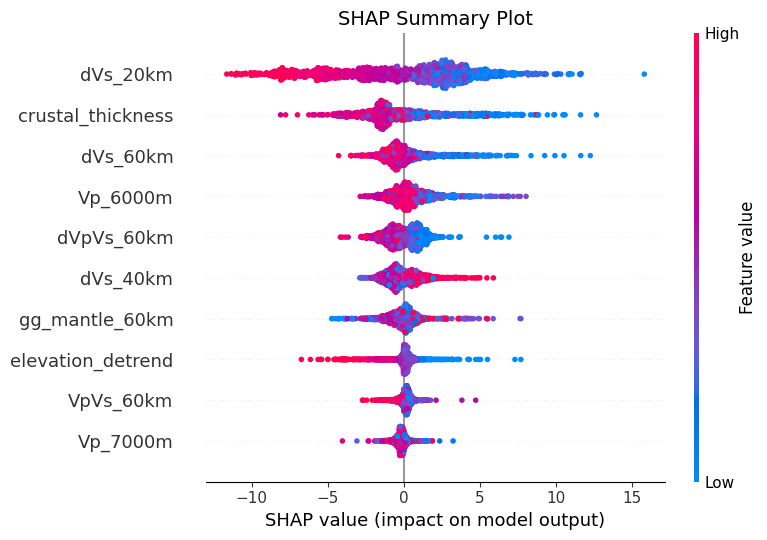

In [15]:
xgb_est = model_stack.estimators_[0].named_estimators_['xgb']
explainer = shap.TreeExplainer(xgb_est)
sample_shap = X_scaled[:1500]
shap_values = explainer(sample_shap)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_shap, feature_names=fitur_terbaik, show=False)
plt.title('SHAP Summary Plot', fontsize=14)
plt.tight_layout()
plt.savefig('Output_2_SHAP_Plot.png', dpi=300, bbox_inches='tight')
plt.show()

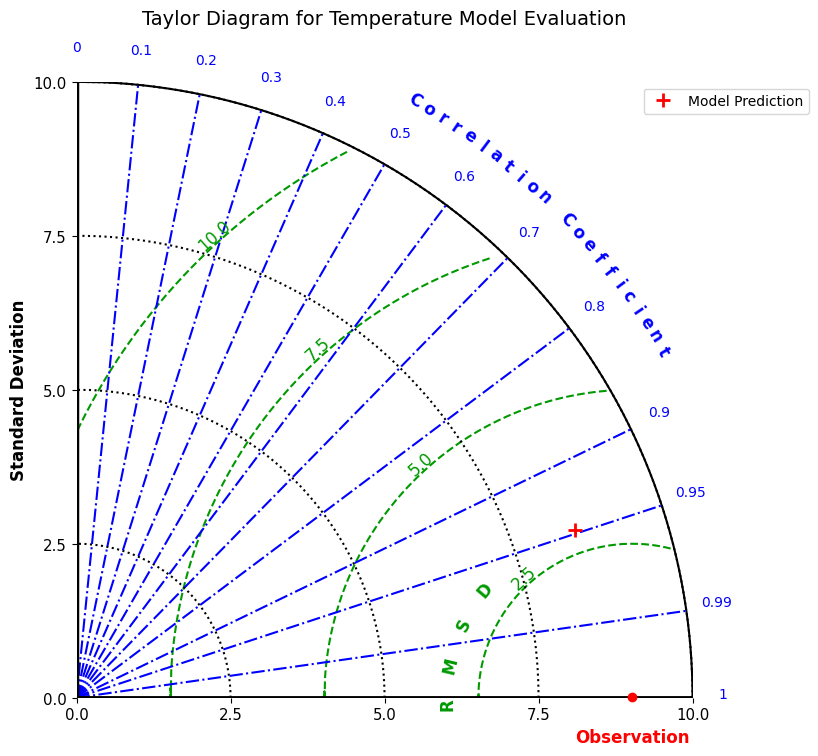

In [16]:
y_act_1000 = y_multi[:, 0]
y_pred_1000 = y_pred_cv_stack[:, 0]
sdev = np.array([np.std(y_act_1000), np.std(y_pred_1000)])
crmse = np.array([0, np.sqrt(np.mean(((y_pred_1000 - np.mean(y_pred_1000)) - (y_act_1000 - np.mean(y_act_1000)))**2))])
ccoe = np.array([1, np.corrcoef(y_pred_1000, y_act_1000)[0, 1]])
plt.figure(figsize=(8, 8))
sm.taylor_diagram(sdev, crmse, ccoe, markerLabel=['Observation Data', 'Model Prediction'],
                  titleOBS='Observation', markerlegend='on', colOBS='r', markerOBS='o')
plt.title('Taylor Diagram for Temperature Model Evaluation', y=1.08, fontsize=14)
plt.savefig('Output_4_Taylor_Diagram.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
print("Menyimpan model...")
joblib.dump(model_stack, 'model_geotermal_hybrid.pkl', compress=3)
joblib.dump(scaler, 'scaler_geotermal.pkl')
print("Model tersimpan.")

files.download('model_geotermal_hybrid.pkl')
files.download('scaler_geotermal.pkl')
files.download('Ablation_Study_Comparison_Table.xlsx')
files.download('Feature_Importance_Ranking.xlsx')
print("Download dikirim.")

Menyimpan model...
Model tersimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download dikirim.
